#####VaR#####
Number of VaR breaches:  48
That is a probability of:  0.012096774193548387
Kupiec Test statistic is:  1.6515917638078008
p-value is:  0.1987424219348731
Christoffersen Test statistic is:  9.107253000247852
p-value is:  0.0025459793059213376
Conditional Coverage Test statistic is:  10.758844764055652
p-value is:  0.00461048425958278

#####ES#####
Observed Z2 = 1.670869
Acerbi Szekely p-value = 0.1449


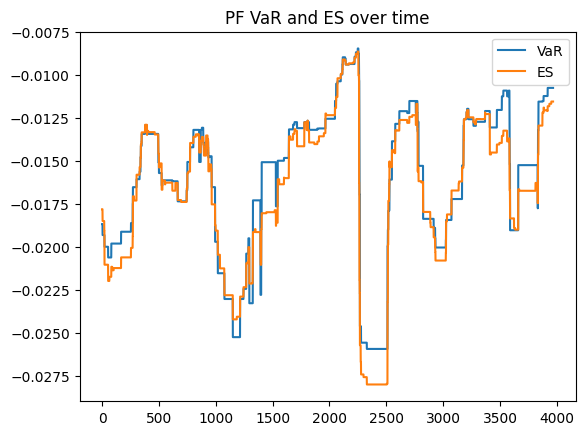

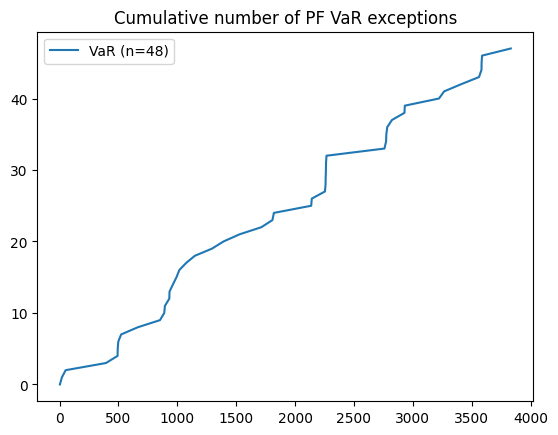

In [36]:
import yfinance as yf
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
from scipy.stats import chi2
from arch import arch_model


class Var_ES_Engine:
    def __init__(self,tickers, start,end, pf_weights):
        self.tickers = tickers
        self.start = start
        self.end = end
        self.pf_weights = pf_weights

        self.master_df = self.load_and_clean_data()


    def load_and_clean_data(self):
        close_dfs = []

        for ticker in self.tickers:
            df = yf.download(
                ticker,
                start=self.start,
                end=self.end,
                auto_adjust=False,
                progress=False
            )
            if isinstance(df.columns, pd.MultiIndex):
                df.columns = df.columns.get_level_values(0)

            temp_df = df[["Adj Close"]].copy()
            temp_df.columns = [ticker]
            close_dfs.append(temp_df)

        # Create the master DataFrame
        master_df = pd.concat(close_dfs, axis=1)

        # Forward-fill missing observations
        master_df = master_df.ffill()

        # Store it as a class attribute
        return master_df.reset_index()

    def plot_data(self):
        plt.figure(figsize=(10, 4))

        for ticker, color in zip(self.tickers, self.colors):
            plt.plot(
                self.master_df['Date'],
                self.master_df[ticker],
                label=ticker,
                color=color
            )

        plt.title('PF Close Value')
        plt.legend()
        plt.grid(True)
        plt.show()

    def calculate_pf_value(self):
        df = self.master_df.copy()

        df['^GSPC'] = df['^GSPC'] / df['EURUSD=X']
        df['IEF'] = df['IEF'] / df['EURUSD=X']
        df['EMLC'] = df['EMLC'] / df['EURUSD=X']
        df['^N225'] = df['^N225'] / df['EURJPY=X']

        weighted_prices = df[self.tickers] * self.pf_weights
        df['PF Value'] = weighted_prices.sum(axis=1)

        self.master_df = df

        return self.master_df

    def calculate_pf_returns(self):
        df = self.master_df.copy()

        # Convert asset prices to a common currency (EUR)
        df["^GSPC"] = df["^GSPC"] / df["EURUSD=X"]
        df["IEF"] = df["IEF"] / df["EURUSD=X"]
        df["EMLC"] = df["EMLC"] / df["EURUSD=X"]
        df["^N225"] = df["^N225"] / df["EURJPY=X"]

        asset_prices = df[self.tickers].copy()

        # Asset returns
        asset_returns = asset_prices.pct_change()

        weights = np.asarray(self.pf_weights, dtype=float)

        if len(weights) != len(self.tickers):
            raise ValueError("Weights and tickers must have equal lengths.")

        if not np.isclose(weights.sum(), 1.0):
            raise ValueError("Portfolio weights must sum to 1.")

        # Constant-weight portfolio return
        df["returns"] = asset_returns.dot(weights)

        # Remove observations with incomplete returns
        df = df.dropna(subset=["returns"]).reset_index(drop=True)

        return df

    def plot_returns(self):
        df = self.master_df.copy()
        df['returns sorted'] = df['returns'].sort_values().reset_index(drop=True)
        
        plt.plot(df['returns sorted'], label="PF Returns", color='green')
        plt.hlines(y=0, xmin=0, xmax=len(df['returns sorted']), linestyles=['--'])
        plt.show()

    @staticmethod
    def calculate_VaR(returns, alpha=0.01):
        returns = np.asarray(returns)
        returns = returns[~np.isnan(returns)]

        if len(returns) == 0:
            raise ValueError("No valid returns provided.")

        if not 0 < alpha < 1:
            raise ValueError("alpha must be between 0 and 1.")

        VaR = np.quantile(returns, alpha)

        return VaR
    
    @staticmethod
    def calculate_ES(returns, alpha=0.025):
        returns = np.asarray(returns)
        returns = returns[~np.isnan(returns)]

        if len(returns) == 0:
            raise ValueError("No valid returns provided.")

        if not 0 < alpha < 1:
            raise ValueError("alpha must be between 0 and 1.")

        VaR = np.quantile(returns, alpha)

        tail_returns = returns[returns <= VaR]
        ES = tail_returns.mean()

        return ES

    def calculate_rolling_VaR_and_ES(self, VaR_alpha, ES_alpha, window_size):
        df = self.calculate_pf_returns()
        returns = df["returns"].to_numpy()

        VaRs = []
        ESs = []

        for end_idx in range(window_size, len(returns)):
            window_returns = returns[end_idx - window_size:end_idx]

            VaR = self.calculate_VaR(
                window_returns, VaR_alpha
            )
            ES = self.calculate_ES(
                window_returns, ES_alpha
            )

            VaRs.append(VaR)
            ESs.append(ES)

        # The forecast from each window applies to the NEXT return
        test_returns = returns[window_size:]

        return test_returns, np.asarray(VaRs), np.asarray(ESs)


    def find_VaR_breaches(self,returns,VaRs):
        breaches = 0
        idx = 0
        breach_idx = []
        for l1,l2 in zip(returns,VaRs):
            if l1 < l2:
                breaches += 1
                breach_idx.append(idx)
            idx += 1
        pi_hat = breaches/len(VaRs)
        print('Number of VaR breaches: ',breaches)
        print('That is a probability of: ',pi_hat)
        return breaches,breach_idx

    def kupiec(self,VaR_alpha,breaches,n):
        pi_hat = breaches/n
        element1 = breaches * np.log(VaR_alpha)+(n-breaches)*np.log(1-VaR_alpha)
        element2 = breaches * np.log(pi_hat) + (n-breaches)*np.log(1-pi_hat)
        lr_POF = -2*(element1 - element2)
        p_value = chi2.sf(lr_POF,df = 1)
        print('Kupiec Test statistic is: ', lr_POF)
        print('p-value is: ', p_value)
        return lr_POF

    def christoffersen(self,returns,VaRs):
        exceptions = (np.asarray(returns) < np.asarray(VaRs)).astype(int)
        previous = exceptions[:-1]
        current = exceptions[1:]

        n_00 = np.sum((previous == 0) & (current == 0))
        n_01 = np.sum((previous == 0) & (current == 1))
        n_10 = np.sum((previous == 1) & (current == 0))
        n_11 = np.sum((previous == 1) & (current == 1))
        
        pi_hat = (n_01 + n_11)/(n_00+n_01+n_10+n_11)
        pi_01 = n_01/(n_00+n_01)
        pi_11 = n_11/(n_10+n_11)

        element1 = (n_00+n_10)*np.log(1-pi_hat)+(n_01+n_11)*np.log(pi_hat)
        element2 = n_00 * np.log(1-pi_01)+n_01*np.log(pi_01)+n_10*np.log(1-pi_11)+n_11*np.log(pi_11)
        
        lr_ind = -2*(element1 - element2)
        p_value = chi2.sf(lr_ind,df = 1)
        print('Christoffersen Test statistic is: ', lr_ind)
        print('p-value is: ', p_value)
        return lr_ind

    def conditional_coverage(self,lr_pof,lr_ind):
        lr_cc = lr_pof + lr_ind
        p_value_cc = chi2.sf(lr_cc, df=2)
        print('Conditional Coverage Test statistic is: ', lr_cc)
        print('p-value is: ', p_value_cc)
        return lr_cc

    def acerbi_Szekely(self, returns, VaRs,ESs,alpha=0.025, n_sims=10000):
        returns = np.asarray(returns)
        VaRs = np.asarray(VaRs)
        ESs = np.asarray(ESs)
        T = len(returns)

        hits_obs = returns < VaRs
        z2_obs = (1.0 / (T * alpha)) * np.sum((returns * hits_obs) / ESs) + 1.0
        print(f"Observed Z2 = {z2_obs:.6f}")

        #Fit GARCH model
        am = arch_model(returns, mean='Zero',vol = 'GARCH',p = 1, q = 1,dist = 't',rescale=True)
        res = am.fit(disp='off')

        scale = res.scale

        forecasts = res.forecast(horizon = T, method='simulation', simulations = n_sims)
        
        sim_paths_scaled = forecasts.simulations.values[0, :, :]

        sim_paths = sim_paths_scaled / scale

        sim_hits = sim_paths < VaRs

        z2_null_dist = (1.0 / (T * alpha)) * np.sum((sim_paths * sim_hits) / ESs, axis=1) + 1.0
        p_value = np.mean(z2_null_dist <= z2_obs)
        print(f"Acerbi Szekely p-value = {p_value:.4f}")

        return {
            "z2_stat": z2_obs,
            "p_value": p_value,
            "null_distribution": z2_null_dist,
            "sim_returns": sim_paths
        }                


#####Setup

tickers = ['^GSPC','^N225','IEF','EMLC','EURUSD=X','EURJPY=X']
start = '2010-07-23'
end = '2026-09-28'
colors = ['blue', 'yellow', 'orange', 'green', 'purple']

pf_weights = [0.01241,0.126648,0.209178,0.651764,0,0]

engine = Var_ES_Engine(tickers = tickers,
                       start = start,
                       end = end,
                       pf_weights = pf_weights)

###Execution
print('#####VaR#####')
returns = engine.calculate_pf_returns()

VaR_alpha = 0.01
ES_alpha = 0.025

test_returns, VaRs, ESs = engine.calculate_rolling_VaR_and_ES(
    VaR_alpha=VaR_alpha,
    ES_alpha=ES_alpha,
    window_size=250
)

VaR_breaches, VaR_breach_idx = engine.find_VaR_breaches(
    test_returns, VaRs
)

lr_pof = engine.kupiec(VaR_alpha,VaR_breaches, n = len(VaRs))
lr_ind = engine.christoffersen(test_returns, VaRs)
engine.conditional_coverage(lr_pof,lr_ind)

print('')
print('#####ES#####')

engine.acerbi_Szekely(test_returns,VaRs,ESs)

plt.plot(VaRs, label = 'VaR')
plt.plot(ESs, label = 'ES')
plt.legend(loc = 'best')
plt.title('PF VaR and ES over time')
plt.show()

plt.plot(VaR_breach_idx,[element for element in range(len(VaR_breach_idx))], label = f'VaR (n={len(VaR_breach_idx)})')
plt.legend(loc = 'best')
plt.title('Cumulative number of PF VaR exceptions')
plt.show()

